<a href="https://colab.research.google.com/github/RAMKISHORMB/AI_ProblemSolving_-RA2411077050004-/blob/main/Pima_Diabetes_ML_Task2_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd


df = pd.read_csv("diabetes.csv")


print("First 5 Records:")
print(df.head())


print("\nLast 5 Records:")
print(df.tail())

print("\nShape of Dataset:")
print(df.shape)
print("Number of Records:", df.shape[0])
print("Number of Features:", df.shape[1])

print("\nDataset Information:")
df.info()

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

First 5 Records:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Last 5 Records:
     Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
763           10      101             76             48      180  32.9   
764            2      122             70             27        0  36.8   
765            5      121             72       

TARGET CLASS DISTRIBUTION
Outcome
0    500
1    268
Name: count, dtype: int64

Target percentage:
Outcome
0    65.1
1    34.9
Name: proportion, dtype: float64

ZERO VALUES IN SELECTED MEDICAL FEATURES
               Zero_Count  Percentage
Glucose                 5        0.65
BloodPressure          35        4.56
SkinThickness         227       29.56
Insulin               374       48.70
BMI                    11        1.43

EXACT DUPLICATE ROWS: 0


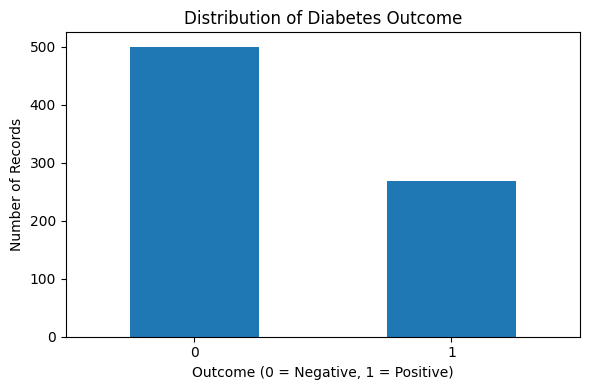

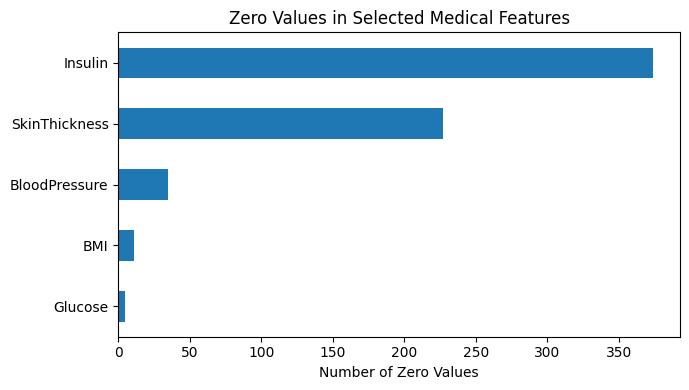

In [4]:

# TASK 2 — Step 2: Data quality and target analysis

# 1. Check the target distribution
print("TARGET CLASS DISTRIBUTION")
print(df["Outcome"].value_counts().sort_index())

print("\nTarget percentage:")
print((df["Outcome"].value_counts(normalize=True).sort_index() * 100).round(2))

# 2. Count zero values in selected medical measurements
zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print("\nZERO VALUES IN SELECTED MEDICAL FEATURES")
zero_counts = (df[zero_columns] == 0).sum()
zero_summary = pd.DataFrame({
    "Zero_Count": zero_counts,
    "Percentage": (zero_counts / len(df) * 100).round(2)
})
print(zero_summary)

# 3. Check exact duplicate records
print("\nEXACT DUPLICATE ROWS:", df.duplicated().sum())

# 4. Visualize class balance
import matplotlib.pyplot as plt

df["Outcome"].value_counts().sort_index().plot(
    kind="bar",
    rot=0,
    figsize=(6, 4)
)
plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome (0 = Negative, 1 = Positive)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# 5. Visualize zero counts
zero_counts.sort_values().plot(
    kind="barh",
    figsize=(7, 4)
)
plt.title("Zero Values in Selected Medical Features")
plt.xlabel("Number of Zero Values")
plt.tight_layout()
plt.show()


Rows after removing exact duplicates: 768
Duplicate rows removed: 0

Zero counts treated as missing:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Class distribution after cleaning:
Outcome
0    500
1    268
Name: count, dtype: int64

Training rows: 614
Held-out test rows: 154

MODEL: Logistic Regression
5-fold CV ROC-AUC: 0.8444 +/- 0.0161

Held-out test metrics:
model                Logistic Regression
cv_accuracy_mean                0.762202
cv_precision_mean               0.648607
cv_recall_mean                  0.700997
cv_f1_mean                      0.672385
cv_roc_auc_mean                 0.844381
cv_roc_auc_std                  0.016074
test_accuracy                   0.733766
test_precision                  0.603175
test_recall                     0.703704
test_f1                         0.649573
test_roc_auc                    0.812593

Classification report:
              precision    recall  f1-score 

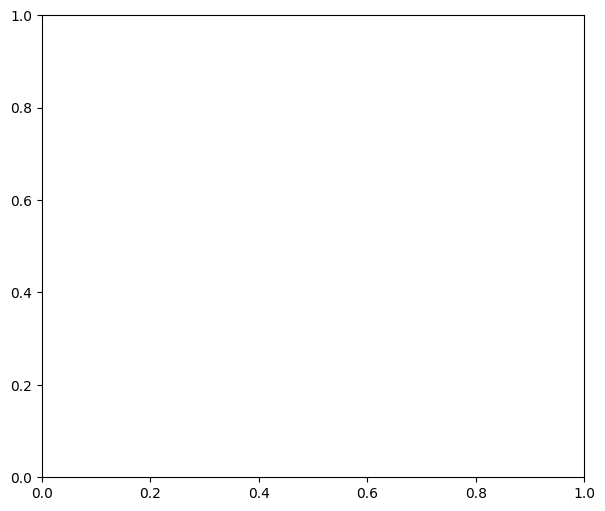

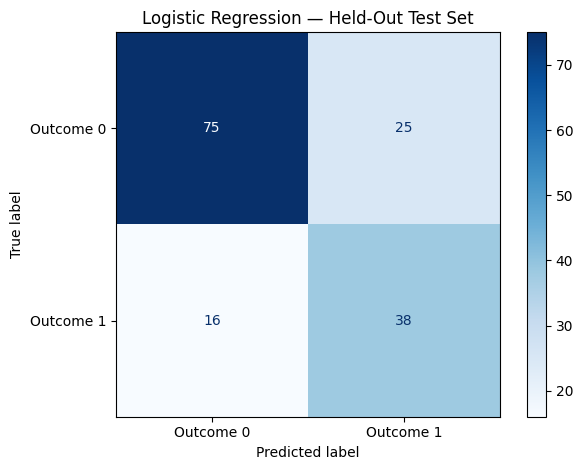


MODEL: Random Forest
5-fold CV ROC-AUC: 0.8322 +/- 0.0237

Held-out test metrics:
model                Random Forest
cv_accuracy_mean          0.771971
cv_precision_mean         0.695011
cv_recall_mean            0.630786
cv_f1_mean                0.659681
cv_roc_auc_mean           0.832183
cv_roc_auc_std            0.023682
test_accuracy              0.75974
test_precision            0.666667
test_recall                0.62963
test_f1                   0.647619
test_roc_auc              0.824444

Classification report:
              precision    recall  f1-score   support

   Outcome 0       0.81      0.83      0.82       100
   Outcome 1       0.67      0.63      0.65        54

    accuracy                           0.76       154
   macro avg       0.74      0.73      0.73       154
weighted avg       0.76      0.76      0.76       154



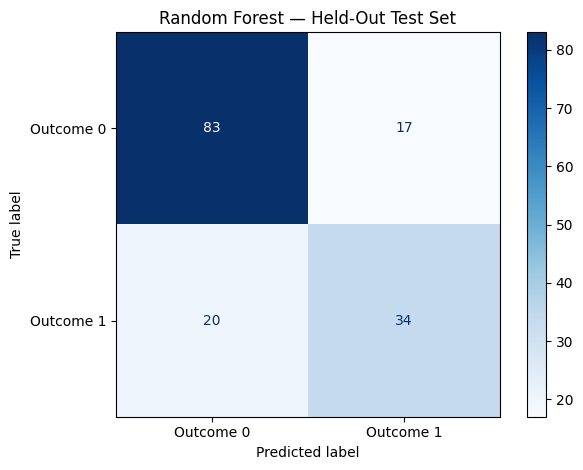

<Figure size 640x480 with 0 Axes>


FINAL MODEL COMPARISON


,model,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_roc_auc_std,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,Logistic Regression,0.7622,0.6486,0.7010,0.6724,0.8444,0.0161,0.7338,0.6032,0.7037,0.6496,0.8126
1,Random Forest,0.7720,0.6950,0.6308,0.6597,0.8322,0.0237,0.7597,0.6667,0.6296,0.6476,0.8244



Saved result files to: /content/results


In [5]:

# TASK 2 — Step 3: Preprocess, train, cross-validate and evaluate

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay,
    RocCurveDisplay
)

# 1. Validate and clean the data
required = [
    "Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Missing required columns: {missing}")

data = df[required].copy()
for col in required:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["Outcome"])
data = data[data["Outcome"].isin([0, 1])].copy()
data["Outcome"] = data["Outcome"].astype(int)

duplicates_removed = int(data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)

# In this dataset, zeros in these measurements are treated as missing.
# This is a documented assumption, not a universal clinical rule.
zero_columns = [
    "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"
]
zero_counts_before = (data[zero_columns] == 0).sum()

for col in zero_columns:
    data.loc[data[col] == 0, col] = np.nan

print("Rows after removing exact duplicates:", len(data))
print("Duplicate rows removed:", duplicates_removed)
print("\nZero counts treated as missing:")
print(zero_counts_before)
print("\nClass distribution after cleaning:")
print(data["Outcome"].value_counts().sort_index())

# 2. Separate predictors and target
X = data.drop(columns="Outcome")
y = data["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining rows:", len(X_train))
print("Held-out test rows:", len(X_test))

# 3. Define two models with preprocessing inside each pipeline
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

# 4. Cross-validation on training data only
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results = []
fitted_models = {}
predictions_for_export = pd.DataFrame({
    "actual_outcome": y_test.to_numpy()
})

output_dir = Path("results")
model_dir = output_dir / "models"
model_dir.mkdir(parents=True, exist_ok=True)

roc_fig, roc_ax = plt.subplots(figsize=(7, 6))

for name, model in models.items():
    print(f"\n{'=' * 55}")
    print("MODEL:", name)
    print("=" * 55)

    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    print("5-fold CV ROC-AUC:",
          f"{cv_scores['test_roc_auc'].mean():.4f}",
          "+/-",
          f"{cv_scores['test_roc_auc'].std():.4f}")

    # Fit on all training data and evaluate once on the held-out test set
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    row = {
        "model": name,
        "cv_accuracy_mean": cv_scores["test_accuracy"].mean(),
        "cv_precision_mean": cv_scores["test_precision"].mean(),
        "cv_recall_mean": cv_scores["test_recall"].mean(),
        "cv_f1_mean": cv_scores["test_f1"].mean(),
        "cv_roc_auc_mean": cv_scores["test_roc_auc"].mean(),
        "cv_roc_auc_std": cv_scores["test_roc_auc"].std(),
        "test_accuracy": accuracy_score(y_test, y_pred),
        "test_precision": precision_score(y_test, y_pred, zero_division=0),
        "test_recall": recall_score(y_test, y_pred, zero_division=0),
        "test_f1": f1_score(y_test, y_pred, zero_division=0),
        "test_roc_auc": roc_auc_score(y_test, y_prob)
    }
    results.append(row)
    fitted_models[name] = model

    print("\nHeld-out test metrics:")
    print(pd.Series(row).round(4).to_string())
    print("\nClassification report:")
    print(classification_report(
        y_test, y_pred,
        labels=[0, 1],
        target_names=["Outcome 0", "Outcome 1"],
        zero_division=0
    ))

    # Save confusion matrix
    safe_name = name.lower().replace(" ", "_")
    disp = ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred,
        labels=[0, 1],
        display_labels=["Outcome 0", "Outcome 1"],
        cmap="Blues",
        values_format="d"
    )
    disp.ax_.set_title(f"{name} — Held-Out Test Set")
    plt.tight_layout()
    plt.savefig(output_dir / f"{safe_name}_confusion_matrix.png", dpi=160)
    plt.show()
    plt.close()

    # Save predictions and class-1 probabilities
    predictions_for_export[f"{safe_name}_prediction"] = y_pred
    predictions_for_export[f"{safe_name}_probability"] = y_prob

    # Save the fitted preprocessing + model pipeline
    joblib.dump(model, model_dir / f"{safe_name}.joblib")

    # Add the ROC curve to a shared chart
    RocCurveDisplay.from_predictions(
        y_test, y_prob, name=name, ax=roc_ax
    )

# 5. Save and display comparison results
comparison = pd.DataFrame(results).sort_values(
    "cv_roc_auc_mean", ascending=False
)
comparison.to_csv(output_dir / "model_comparison.csv", index=False)
predictions_for_export.to_csv(
    output_dir / "test_predictions.csv", index=False
)

roc_ax.plot([0, 1], [0, 1], linestyle="--", label="Chance baseline")
roc_ax.set_title("ROC Curve Comparison — Held-Out Test Set")
roc_ax.set_xlabel("False Positive Rate")
roc_ax.set_ylabel("True Positive Rate")
roc_ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(output_dir / "roc_comparison.png", dpi=160)
plt.show()
plt.close(roc_fig)

summary = {
    "dataset": "Pima Indians Diabetes Dataset",
    "rows_after_cleaning": int(len(data)),
    "duplicates_removed": duplicates_removed,
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
    "test_fraction": 0.20,
    "random_state": 42,
    "cross_validation": "5-fold stratified CV on training split",
    "zero_as_missing_columns": zero_columns,
    "imputation": "Median imputation fitted inside each training pipeline",
    "models": results,
    "limitation": (
        "Educational model; one held-out split is not external clinical "
        "validation. Not for diagnosis or treatment decisions."
    )
}
with open(output_dir / "experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=float)

print("\nFINAL MODEL COMPARISON")
display(comparison.round(4))
print("\nSaved result files to:", output_dir.resolve())
